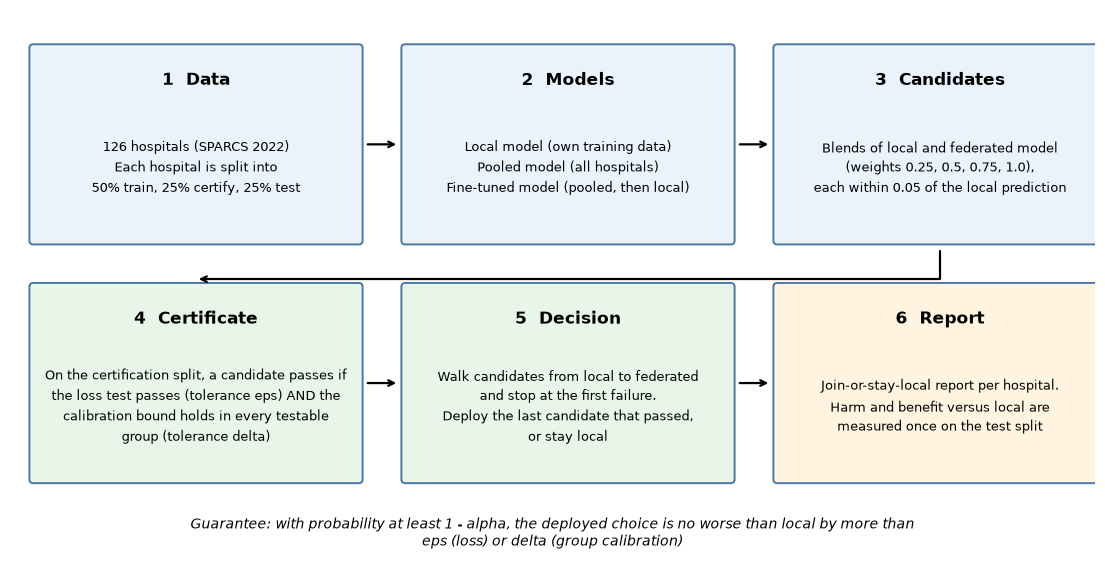

In [2]:
import numpy as np, pandas as pd, matplotlib.pyplot as plt, os
from matplotlib.patches import FancyBboxPatch
os.makedirs("../outputs/figures", exist_ok=True); os.makedirs("../outputs/tables", exist_ok=True)

boxes = [
    ("1  Data", "126 hospitals (SPARCS 2022)\nEach hospital is split into\n50% train, 25% certify, 25% test", "#eaf2fb"),
    ("2  Models", "Local model (own training data)\nPooled model (all hospitals)\nFine-tuned model (pooled, then local)", "#eaf2fb"),
    ("3  Candidates", "Blends of local and federated model\n(weights 0.25, 0.5, 0.75, 1.0),\neach within 0.05 of the local prediction", "#eaf2fb"),
    ("4  Certificate", "On the certification split, a candidate passes if\nthe loss test passes (tolerance eps) AND the\ncalibration bound holds in every testable\ngroup (tolerance delta)", "#e8f5e9"),
    ("5  Decision", "Walk candidates from local to federated\nand stop at the first failure.\nDeploy the last candidate that passed,\nor stay local", "#e8f5e9"),
    ("6  Report", "Join-or-stay-local report per hospital.\nHarm and benefit versus local are\nmeasured once on the test split", "#fff4e0"),
]
fig, ax = plt.subplots(figsize=(14, 7.2)); ax.axis("off"); ax.set_xlim(0, 14); ax.set_ylim(0, 7.2)
w, hgt, gx = 4.2, 2.5, 0.6
xs = [0.3 + c * (w + gx) for c in range(3)]
ys = [4.2, 1.1]
pos = [(xs[c], ys[0]) for c in range(3)] + [(xs[c], ys[1]) for c in range(3)]
for i, ((title, body, col), (x, y0)) in enumerate(zip(boxes, pos)):
    ax.add_patch(FancyBboxPatch((x, y0), w, hgt, boxstyle="round,pad=0.05", fc=col, ec="#4C78A8", lw=1.4))
    ax.text(x + w / 2, y0 + hgt - 0.42, title, ha="center", va="center", fontsize=12, fontweight="bold")
    ax.text(x + w / 2, y0 + 0.95, body, ha="center", va="center", fontsize=9.5, linespacing=1.55)
for i in (0, 1, 3, 4):                                       # arrows within each row
    x, y0 = pos[i]
    ax.annotate("", xy=(x + w + gx - 0.08, y0 + hgt / 2), xytext=(x + w + 0.08, y0 + hgt / 2), arrowprops=dict(arrowstyle="->", lw=1.6))
ax.annotate("", xy=(pos[3][0] + w / 2, pos[3][1] + hgt + 0.1), xytext=(pos[2][0] + w / 2, pos[2][1] - 0.1),
            arrowprops=dict(arrowstyle="->", lw=1.6, connectionstyle="angle,angleA=-90,angleB=180,rad=0"))
ax.text(7, 0.4, "Guarantee: with probability at least 1 - alpha, the deployed choice is no worse than local by more than\neps (loss) or delta (group calibration)",
        ha="center", va="center", fontsize=10, style="italic")
plt.savefig("../outputs/figures/fig1_design.png", dpi=300, bbox_inches="tight"); plt.savefig("../outputs/figures/fig1_design.pdf", bbox_inches="tight"); plt.show()

In [3]:
import yaml, subprocess
with open("../configs/prereg.yaml", encoding="utf-8") as f:
    P = yaml.safe_load(f)

def git(*a):
    return subprocess.run(["git", "-C", "..", *a], capture_output=True, text=True).stdout.strip()

tags = set(git("tag", "-l").split())
rows = []
for k, v in P.items():
    if k.startswith("amendment_"):
        n = k.split("_")[1]
        tag = f"prereg-amendment-{n}"
        commit = git("rev-list", "-n", "1", tag)[:8] if tag in tags else "no tag"
        txt = {kk: vv for kk, vv in v.items()}
        rows.append({"item": k, "date": txt.get("date"), "git_tag": tag if tag in tags else "none", "commit": commit,
                     "summary": txt.get("reason") or txt.get("note") or txt.get("deviation"),
                     "details": " | ".join(f"{kk}: {vv}" for kk, vv in txt.items() if kk not in ("date",))})
T4b = pd.DataFrame(rows)
T4b.to_csv("../outputs/tables/T4b_amendments.csv", index=False)
base = {k: (str(v) if not isinstance(v, (dict, list)) else yaml.safe_dump(v, default_flow_style=True).strip())
        for k, v in P.items() if not k.startswith("amendment_")}
T4a = pd.DataFrame(sorted(base.items()), columns=["setting", "value"]); T4a.to_csv("../outputs/tables/T4a_prereg_settings.csv", index=False)
print(T4a.to_string()); print()
print(T4b[["item", "date", "git_tag", "commit"]].to_string())
for t in ("prereg-v1", "prereg-frozen"):
    print(t, git("rev-list", "-n", "1", t)[:8] if t in tags else "missing")

                          setting                                                                                                                                                                                          value
0                           alpha                                                                                                                                                                                           0.05
1   candidates_local_to_federated                                                                                                                                                                    [0.0, 0.25, 0.5, 0.75, 1.0]
2                       data_rows                                                                                                                                                                                        1794116
3          delta_calibration_grid                                                                   

In [4]:
import sys, platform
from importlib.metadata import version, PackageNotFoundError
pk = ["numpy", "pandas", "scipy", "scikit-learn", "statsmodels", "pyarrow", "matplotlib", "pyyaml"]
sw = [("Python", platform.python_version()), ("Operating system", platform.platform())]
for p in pk:
    try: sw.append((p, version(p)))
    except PackageNotFoundError: sw.append((p, "not installed"))
settings = [
 ("Logistic regression (SPARCS, local, pooled)", "L2, C = 1.0, max 300 iterations (scikit-learn lbfgs)"),
 ("Fine-tuning", "5 L-BFGS iterations from the pooled coefficients on the hospital's training split, L2 1e-5"),
 ("FedAvg / FedProx", "30 rounds, 10 local L-BFGS iterations per round, FedProx mu 0.01, L2 1e-5; not tuned"),
 ("Loss", "log loss clipped to [0, 5]; predictions clipped to [1e-6, 1 - 1e-6]"),
 ("Candidate clipping", "candidate prediction clipped to local prediction +/- 0.05"),
 ("Loss test", "betting bound (Waudby-Smith and Ramdas style), alpha = 0.05, one-sided; empirical-Bernstein as the secondary bound"),
 ("Calibration bound", "paired design: empirical-Bernstein bounds at alpha/4 each on local error and on the mean prediction difference; worst case over the box"),
 ("Fixed sequence", "blends 0.25, 0.5, 0.75, 1.0; stop at first failure"),
 ("Tolerances (headline pairs)", "(eps, delta) = (0.005, 0.01), (0.01, 0.015), (0.02, 0.02)"),
 ("Testable group rule", ">= 20 training deaths in the hospital"),
 ("Hospital inclusion", ">= 100 deaths among adults (126 of 204 hospitals)"),
 ("Splits", "50/25/25 stratified by hospital and outcome; seeds 110-114 (main), 105-109, 100-104 (earlier stages), 200-204 (ICU)"),
 ("MLP", "one hidden layer of 64 units; local: no early stopping, 100 epochs, batch 128, L2 1e-3; pooled: early stopping, 30 epochs, batch 2048"),
 ("Gradient boosting", "HistGradientBoosting, 100 iterations, learning rate 0.1, depth 3, L2 1.0"),
 ("ICU 2012 logistic regression", "C = 0.1; fine-tuning L2 1e-2; features standardised on training rows, clipped at +/- 5"),
 ("Multiple testing", "Holm across hospitals for loss; Bonferroni across a hospital's tested groups for calibration"),
]
T21 = pd.concat([pd.DataFrame(sw, columns=["item", "value"]).assign(type="software"),
                 pd.DataFrame(settings, columns=["item", "value"]).assign(type="fixed setting")], ignore_index=True)
T21.to_csv("../outputs/tables/T21_software_settings.csv", index=False)
print(T21.to_string())

                                           item                                                                                                                                    value           type
0                                        Python                                                                                                                                   3.14.3       software
1                              Operating system                                                                                                                Windows-11-10.0.26300-SP0       software
2                                         numpy                                                                                                                                    2.5.4       software
3                                        pandas                                                                                                                                    3.0.6       software


In [5]:
import glob, os
figs = sorted(os.path.basename(f) for f in glob.glob("../outputs/figures/*.png"))
tabs = sorted(os.path.basename(f) for f in glob.glob("../outputs/tables/*.csv") if not os.path.basename(f).startswith(("cert_full_", "cert_groups_", "cert_bins_", "harm_seed", "bins_", "temporal_", "model_", "loho_", "icu2012_seed", "sim_cert_", "sim_", "pilot_")))
print(len(figs), "figure files:"); print("\n".join(figs))
print("\n", len(tabs), "result and summary tables:"); print("\n".join(tabs))

22 figure files:
fig10_simulation_certified.png
fig11_chosen_blend.png
fig12_price_of_no_harm.png
fig14_baselines.png
fig15_model_class.png
fig16_temporal.png
fig17_icu2012.png
fig18_certifiable_size.png
fig19_intersectional.png
fig1_design.png
fig1_harm_by_candidate.png
fig20_apr_sensitivity.png
fig21_loho.png
fig2_cohort_flow.png
fig2_size_quartiles.png
fig3_heterogeneity.png
fig3_worst_regret.png
fig6_forest.png
fig7_subgroup_calibration.png
fig8_reliability.png
fig9_phase_map.png
figA_clipping_ablation.png

 21 result and summary tables:
F12_price_of_no_harm_grid.csv
T10b_certificate_grid.csv
T11_baselines_seeds105-109.csv
T11b_certificate_seeds110-114.csv
T14_model_class.csv
T15_simulation_grid.csv
T17_temporal.csv
T18_icu2012.csv
T18b_icu2012_by_unit.csv
T19_apr_sensitivity.csv
T1_cohort.csv
T21_software_settings.csv
T22_min_certified_size.csv
T2_hospital_characteristics.csv
T3_features.csv
T4a_prereg_settings.csv
T4b_amendments.csv
T5_power.csv
T8_subgroup_calibration.csv
T_inte